# Secure Pay Vision: Credit Card Fraud Detection

Compares **Logistic Regression** and **Random Forest** on the Kaggle credit card fraud dataset
(284,807 transactions, 492 frauds) using one evaluation protocol:

1. Stratified train/test split of the **original, imbalanced** data. The test set is never resampled.
2. Imbalance handling (none, class weights, undersampling, SMOTE) is applied to the **training data only**.
3. Models are compared on fraud-class metrics (precision, recall, F1, PR-AUC, ROC-AUC) and confusion matrices, not accuracy alone.

Download `creditcard.csv` from Kaggle and place it at `data/creditcard.csv` (see the README).

## 1. Setup

In [22]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # so `src` is importable from notebooks/

import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import load_data, make_splits
from src.train import run_experiments
from src.evaluate import majority_baseline_accuracy, plot_roc, plot_pr

SEED = 42
DATA_PATH = os.environ.get("CREDITCARD_CSV", "./data/creditcard.csv")

## 2. Load and inspect the data

In [23]:
df = load_data(DATA_PATH)
print(df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
df.head()

(284807, 31)
Missing values: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [24]:
counts = df["Class"].value_counts()
print(counts)
print(f"Fraud rate: {df['Class'].mean():.4%}")
df.groupby("Class")["Amount"].describe()

Class
0    284315
1       492
Name: count, dtype: int64
Fraud rate: 0.1727%


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


The dataset is extremely imbalanced. A model that predicts "legit" for every transaction already scores about 99.83% accuracy,
so **accuracy cannot be used to judge fraud detection here**.

## 3. Train/test split (test set stays imbalanced)

In [25]:
X_train, X_test, y_train, y_test = make_splits(df, test_size=0.2, seed=SEED)
print(f"Train: {len(X_train):,} rows, {int(y_train.sum())} fraud")
print(f"Test : {len(X_test):,} rows, {int(y_test.sum())} fraud ({y_test.mean():.4%})")
print(f"Always-predict-legit accuracy on test set: {majority_baseline_accuracy(y_test):.4f}")

Train: 227,845 rows, 394 fraud
Test : 56,962 rows, 98 fraud (0.1720%)
Always-predict-legit accuracy on test set: 0.9983


## 4. Train and evaluate

Every model/strategy pair is trained on the training split and scored on the same untouched test split.
`smote` requires `imbalanced-learn`; remove it from the list if you haven't installed it.
Lower `n_estimators` (e.g. 100) for a faster run.

In [26]:
rows, scores, fitted = run_experiments(
    X_train, X_test, y_train, y_test,
    models=["logreg", "rf"],
    strategies=["none", "class_weight", "undersample", "smote"],
    seed=SEED, n_estimators=200,
)
results = pd.DataFrame(rows).set_index("run")
results[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "tp", "fn", "fp"]].round(4)

Training Logistic Regression | none ...
Training Logistic Regression | class_weight ...
Training Logistic Regression | undersample ...
Training Logistic Regression | smote ...
Training Random Forest | none ...
Training Random Forest | class_weight ...
Training Random Forest | undersample ...
Training Random Forest | smote ...


,accuracy,precision,recall,f1,roc_auc,pr_auc,tp,fn,fp
run,,,,,,,,,
Logistic Regression | none,0.9991,0.8267,0.6327,0.7168,0.9605,0.7414,62,36,13
Logistic Regression | class_weight,0.9755,0.0610,0.9184,0.1144,0.9721,0.7190,90,8,1386
Logistic Regression | undersample,0.9708,0.0516,0.9184,0.0977,0.9752,0.4578,90,8,1655
Logistic Regression | smote,0.9741,0.0578,0.9184,0.1088,0.9708,0.7245,90,8,1467
Random Forest | none,0.9996,0.9419,0.8265,0.8804,0.9623,0.8730,81,17,5
Random Forest | class_weight,0.9995,0.9610,0.7551,0.8457,0.9572,0.8589,74,24,3
Random Forest | undersample,0.9661,0.0447,0.9184,0.0852,0.9749,0.6942,90,8,1925
Random Forest | smote,0.9994,0.8265,0.8265,0.8265,0.9685,0.8760,81,17,17


## 5. ROC and precision-recall curves

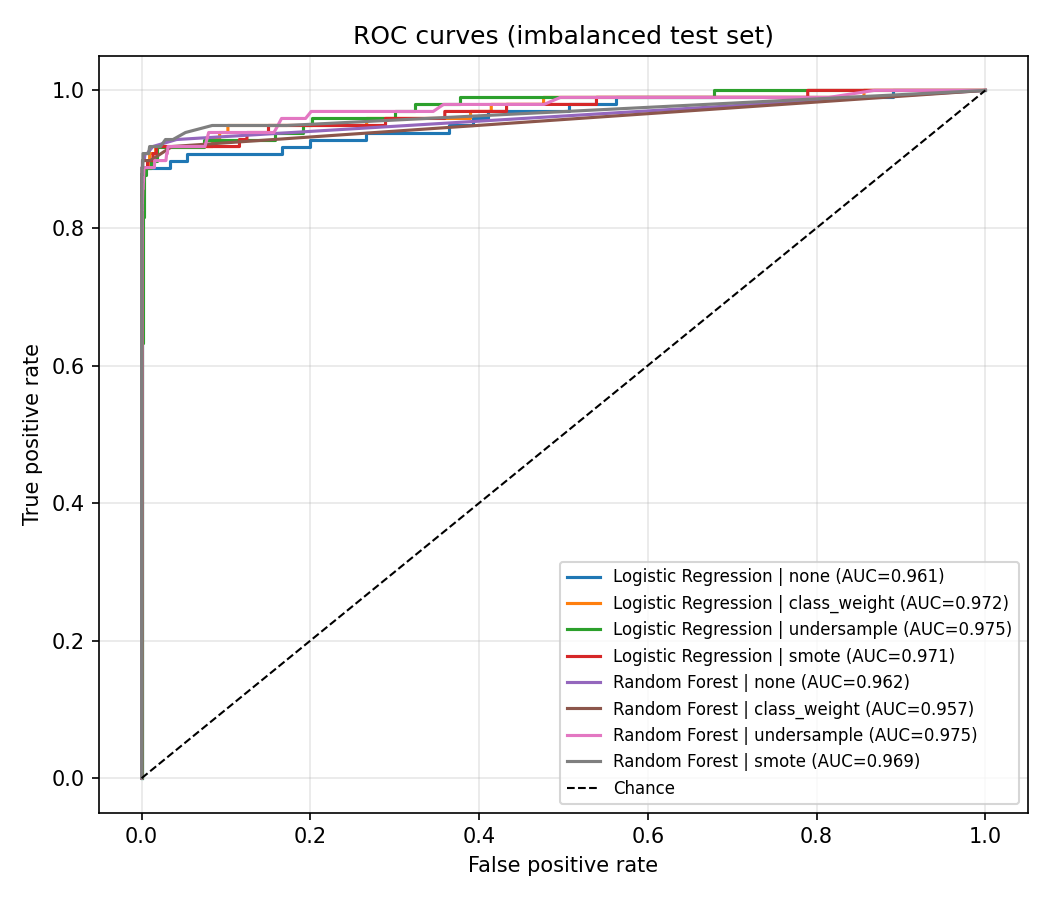

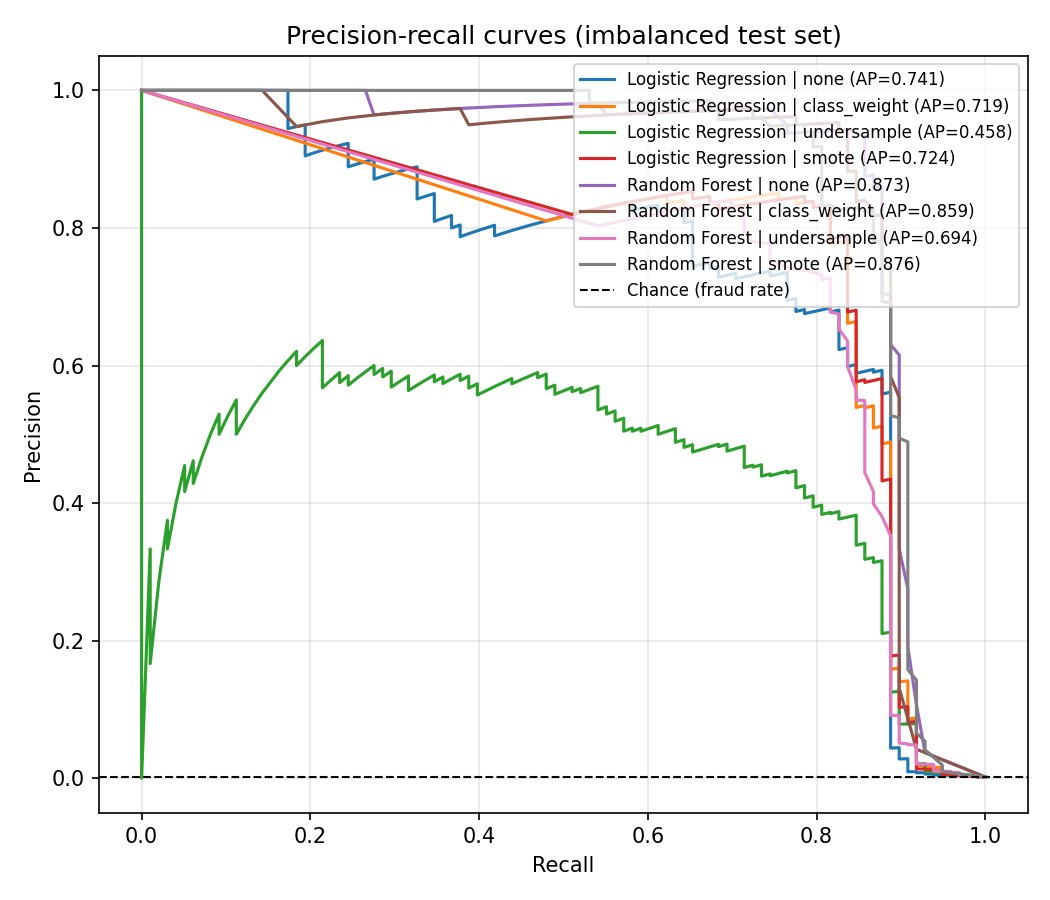

In [27]:
plot_roc(y_test, scores, "../results/roc_curve.png")
plot_pr(y_test, scores, "../results/pr_curve.png")
from IPython.display import Image, display
display(Image("../results/roc_curve.png")); display(Image("../results/pr_curve.png"))

## 6. Confusion matrices: how many frauds are caught and missed?

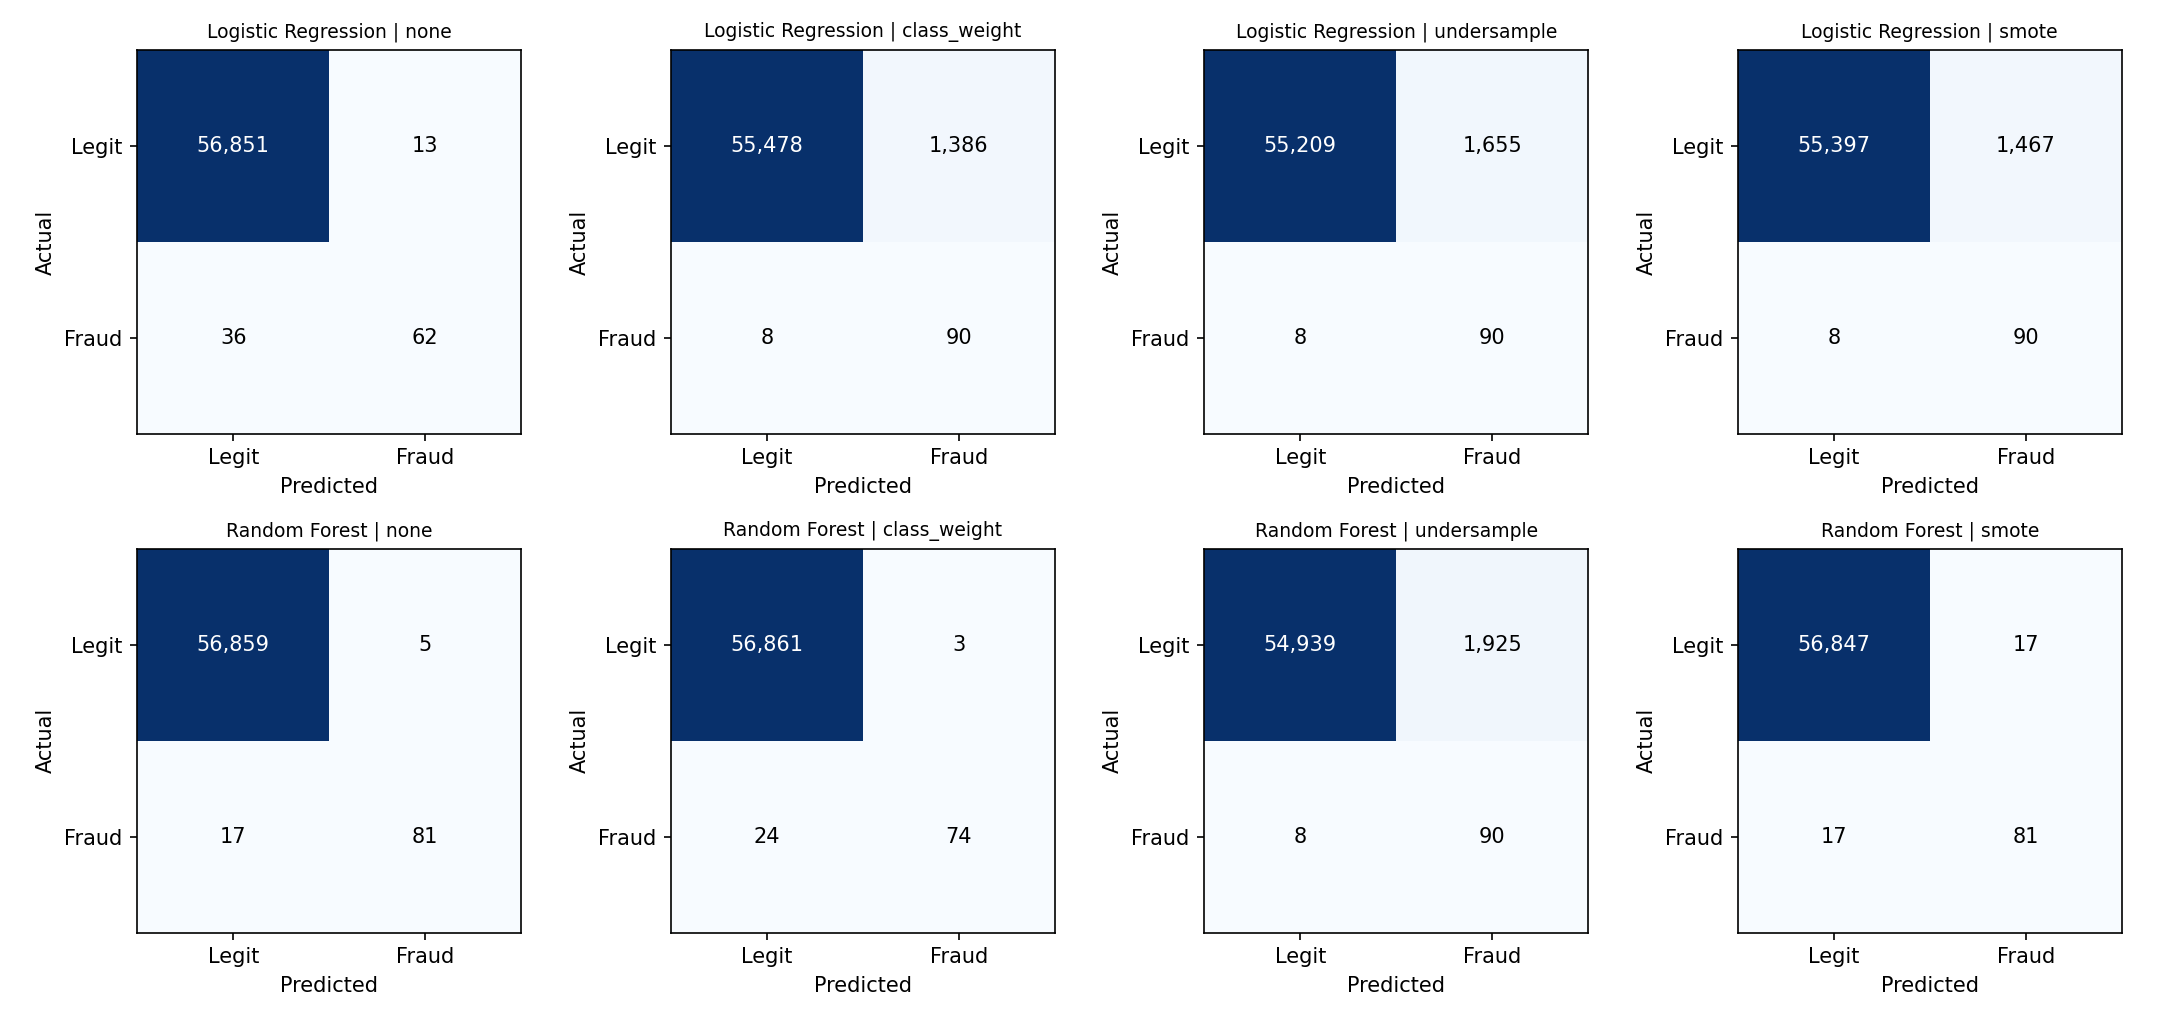

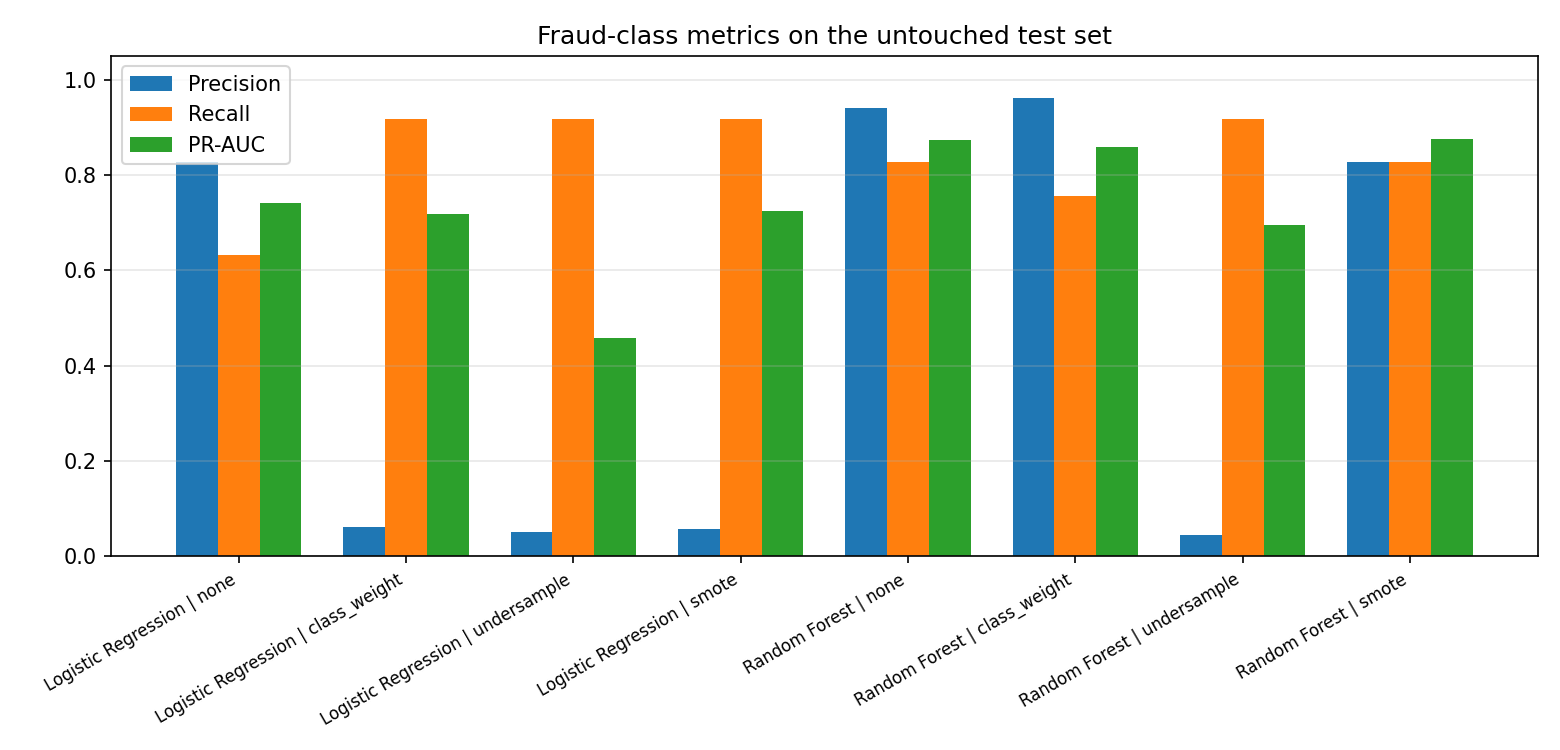

In [28]:
from src.evaluate import plot_confusion_matrices, plot_model_comparison
plot_confusion_matrices(rows, "../results/confusion_matrix.png")
plot_model_comparison(rows, "../results/model_comparison.png")
display(Image("../results/confusion_matrix.png")); display(Image("../results/model_comparison.png"))

## 7. Conclusions

Write your conclusions here **after running the notebook on the real dataset**. Base them on recall, precision and PR-AUC on the
imbalanced test set, and note the trade-off between caught frauds (recall) and false alarms (precision).
Results use a single split and the default 0.5 threshold, so treat small differences between models with caution.